In [1]:
import mido
import os
import fluidsynth

import matplotlib.pyplot as plt 
import numpy as np
import pandas as pd
from collections import Counter

In [2]:
groove_path = "./data/groove-v1.0.0-midionly/groove/"
dir_path = groove_path + "drummer1/session1/"
# track_name = "222_rock-halftime_140_fill_4-4.mid" # IT"S JUST A FILL
track_name = "202_rock-halftime_140_beat_4-4.mid"
midifile_path = dir_path + track_name
print(f"MIDI FILE PATH: {midifile_path}")
os.listdir(dir_path)[:10] # get 10 for example

MIDI FILE PATH: ./data/groove-v1.0.0-midionly/groove/drummer1/session1/202_rock-halftime_140_beat_4-4.mid


['222_rock-halftime_140_fill_4-4.mid',
 '156_latin-brazilian-baiao_95_fill_4-4.mid',
 '124_funk_95_fill_4-4.mid',
 '228_rock-halftime_140_fill_4-4.mid',
 '62_jazz_125_fill_4-4.mid',
 '11_jazz-funk_116_fill_4-4.mid',
 '97_neworleans-funk_84_fill_4-4.mid',
 '6_jazz-funk_116_fill_4-4.mid',
 '250_funk-purdieshuffle_130_fill_4-4.mid',
 '4_jazz-funk_116_beat_4-4.mid']

In [3]:
mid = mido.MidiFile(midifile_path)
mid.print_tracks(True) # print only meta information
print(f"Ticks per quarter note: {mid.ticks_per_beat}")

multiplier = 8
TICKS_PER_STEP =int( mid.ticks_per_beat/multiplier ) # quarter in half -> 8th notes

=== Track 0
MetaMessage('set_tempo', tempo=428571, time=0)
MetaMessage('time_signature', numerator=4, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
MetaMessage('key_signature', key='C', time=0)
MetaMessage('end_of_track', time=1)
Ticks per quarter note: 480


In [4]:
# helper functions

def get_notes(mid):
  notes = []

  for track in mid.tracks:
      current_time = 0
      for msg in track:
          current_time += msg.time
          if msg.type == 'note_on' and msg.velocity > 0:
              # print(msg.note)
              note = {
                  'pitch': int(msg.note),
                  'start': current_time,
                  'end': None,
                  'length': None
              }
              notes.append(note)
          elif msg.type == 'note_off' or (msg.type == 'note_on' and msg.velocity == 0):
              for n in notes:
                  if n['pitch'] == msg.note and n['end'] is None:
                      n['end'] = current_time
                      n['length'] = n['end'] - n['start']
  return notes

def viz_notes(notes, approved=None):
  plt.figure(figsize=(12, 6))
  print(f"filter: {approved}")
  for note in notes:
      if approved is not None and note["pitch"] not in approved:
        continue # skip note not in 
      plt.plot([note['start'], note['end']], [note['pitch'], note['pitch']], marker='o', color='b')
  plt.xlabel('Time (ticks)')
  plt.ylabel('Pitch (MIDI note number)')
  plt.title('Piano Roll: Note Distribution')
  plt.grid(True)
  plt.show()


def analize_notes(notes, num_most_common=4):
  pitches = [note["pitch"] for note in notes] # extract
  pitch_counter = Counter(pitches) # create a counter
  most_common_pitches = pitch_counter.most_common(num_most_common)

  for i, value in enumerate(most_common_pitches):
    pitch, frequency = value
    print(f"{i + 1}: Most frequent pitch: {pitch} (appears {frequency} times)")
  
  return [val[0] for val in most_common_pitches]

convert

1: Most frequent pitch: 36 (appears 251 times)
2: Most frequent pitch: 51 (appears 226 times)
3: Most frequent pitch: 42 (appears 207 times)
4: Most frequent pitch: 44 (appears 161 times)
5: Most frequent pitch: 38 (appears 158 times)
filter: [36, 51, 42, 44, 38]


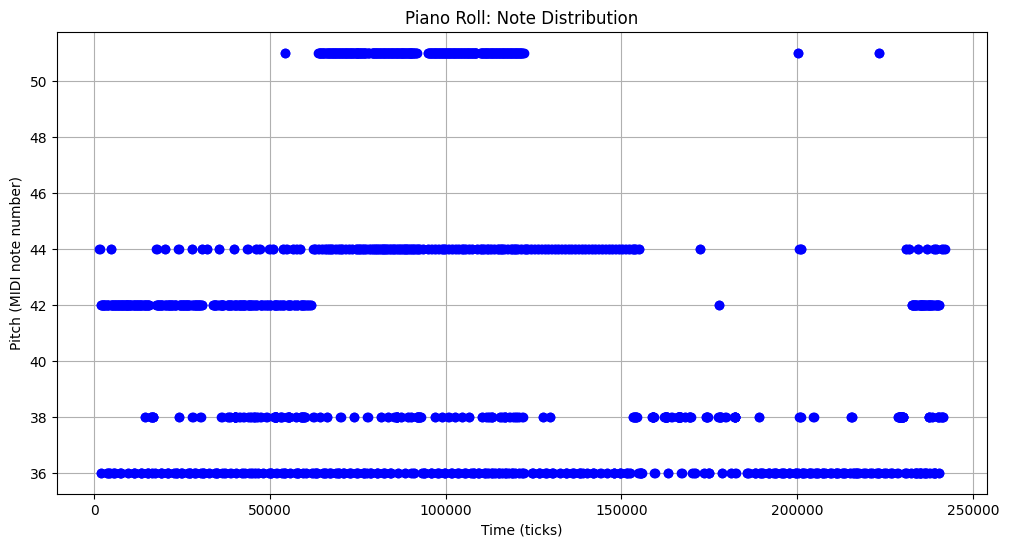

[{'pitch': 40, 'start': 970, 'end': 1014, 'length': 44}, {'pitch': 40, 'start': 1014, 'end': 1084, 'length': 70}, {'pitch': 44, 'start': 1469, 'end': 1582, 'length': 113}, {'pitch': 36, 'start': 1930, 'end': 2042, 'length': 112}, {'pitch': 42, 'start': 1947, 'end': 2060, 'length': 113}, {'pitch': 42, 'start': 2181, 'end': 2294, 'length': 113}, {'pitch': 42, 'start': 2416, 'end': 2530, 'length': 114}, {'pitch': 42, 'start': 2650, 'end': 2764, 'length': 114}, {'pitch': 40, 'start': 2890, 'end': 3003, 'length': 113}, {'pitch': 42, 'start': 2907, 'end': 3020, 'length': 113}, {'pitch': 42, 'start': 3143, 'end': 3256, 'length': 113}, {'pitch': 22, 'start': 3366, 'end': 3479, 'length': 113}, {'pitch': 36, 'start': 3571, 'end': 3684, 'length': 113}, {'pitch': 42, 'start': 3586, 'end': 3700, 'length': 114}, {'pitch': 42, 'start': 3812, 'end': 3924, 'length': 112}, {'pitch': 42, 'start': 4046, 'end': 4159, 'length': 113}, {'pitch': 36, 'start': 4056, 'end': 4168, 'length': 112}, {'pitch': 46, 's

In [5]:
midi_file = mido.MidiFile(midifile_path)

notes = get_notes(midi_file)
most_freq = analize_notes(notes, 5)
viz_notes(notes, most_freq)
print(notes)

### Count unique notes!

In [6]:
def count_unique_notes(dir: str) -> set[str]:
  file_names: list[str] = os.listdir(dir)
  notes = set()
  full_names = []

  for file_name in file_names:
    if not file_name.endswith(".mid"):
      # print("NOT MIDI")
      continue

    full_name = dir + "/" + file_name
    full_names.append(full_name)

    midi_file = mido.MidiFile(full_name)

    for msg in midi_file.tracks[0]:
      if msg.type == "note_on":
        notes.add(msg.note)
  
  return notes


notes = count_unique_notes(dir_path)
print("NOTES:", notes)

NOTES: {22, 26, 36, 37, 38, 40, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 55, 58, 59}


### Helper functions for reading all the files

In [7]:
def full_path(dir_name, file_name):
  return dir_name + file_name
  
def read_files(dir_path: str) -> set[str]:
  print("dir path", dir_path)
  rum_files = set()
  if not os.path.isdir(dir_path):
    print("IT'S NOT A DIR!!!")
    return rum_files.union( set(os.listdir(dir_path)))

  for file_name in os.listdir(dir_path):
    fp = full_path(dir_path, file_name)

    if os.path.isdir(fp):
      files_in_dir: set[str] = read_files(fp)
      print("read some files!", files_in_dir)
      if not files_in_dir is None:
        rum_files.union(files_in_dir)
  
  return rum_files

# FIXED

# TODO: review it
import os

def read_files(dir_path: str) -> set[str]:
    rum_files = set()
    if not os.path.isdir(dir_path):
        print(f"Warning: {dir_path} is not a directory!")
        return rum_files

    for item in os.listdir(dir_path):
        full_path = os.path.join(dir_path, item)
        if os.path.isdir(full_path):
            # Recursively read subdirectory
            rum_files.update(read_files(full_path))
        else:
            # Add file to the set
            rum_files.add(full_path)

    return rum_files


In [8]:
outcome = read_files(groove_path)
print(outcome)

{'./data/groove-v1.0.0-midionly/groove/drummer7/session2/31_rock_75_fill_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer7/session2/125_hiphop_140_fill_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer8/session1/Icon\r', './data/groove-v1.0.0-midionly/groove/drummer3/session1/43_rock_120_beat_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer1/session1/236_rock-halftime_140_fill_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer7/session1/14_jazz_100_beat_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer7/session1/17_hiphop_100_beat_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer1/session1/210_rock-halftime_140_fill_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer3/session1/29_rock_120_beat_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer1/session1/185_reggae_78_fill_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer7/session3/119_rock_95_beat_4-4.mid', './data/groove-v1.0.0-midionly/groove/drummer8/session1/15_hiphop_94_beat_4-4.

In [9]:
all_notes =set() 

path = groove_path

directories= [os.listdir(path +drummer_file) if os.path.isdir(path + drummer_file) == True else "" for drummer_file in os.listdir(path)]
print(directories)

[['session3', 'session2', 'session1', 'Icon\r'], ['session1', 'Icon\r'], ['session2', 'session1', 'Icon\r'], '', ['session3', 'eval_session', 'session2', 'session1', 'Icon\r'], '', ['session3', 'eval_session', 'session2', 'session1', 'Icon\r'], ['session1', 'Icon\r'], ['session1', 'Icon\r'], ['eval_session', 'session2', 'session1', 'Icon\r'], ['session3', 'session2', 'session1', 'Icon\r'], '', '', ['eval_session', 'session2', 'session1', 'Icon\r']]


# Convert!

### Mapping

In [10]:
# https://soundprogramming.net/file-formats/general-midi-drum-note-numbers/
# 35 Bass Drum 2
# 36 Bass Drum 1
# 38 Snare Drum 1
# 40 Snare Drum 2
# 42 Closed Hi-hat
# 44 Pedal Hi-hat
# 46 Open Hi-hat
# 51 Ride Cymbal 1
# 59 Ride Cymbal 2

### BASIC
bass = [35, 36]
snare = [38, 40]
hihat = [
  42, 
#  44,# I thnik we should exclude 44 - pedal hihat, it can produce a lot of noise 
   46
] 


 # 41 Low Tom 2
 # 42 Closed Hi-hat
 # 43 Low Tom 1
 # 44 Pedal Hi-hat
 # 45 Mid Tom 2
 # 46 Open Hi-hat
 # 47 Mid Tom 1
 # 48 High Tom 2
 # 49 Crash Cymbal 1
 # 50 High Tom 1
 # 51 Ride Cymbal 1
 # 52 Chinese Cymbal
 # 53 Ride Bell
 # 54 Tambourine
 # 55 Splash Cymbal
 # 56 Cowbell
 # 57 Crash Cymbal 2
 # 58 Vibra Slap
 # 59 Ride Cymbal 2
### EXTRA
ltom = [41, 43]
mtom = [45, 47]
htom = [48, 50]
crash = [49, 57]
ride = [51, 59]

#### EXTRA EXTRA
china = [52]
bell = [53]
tambourine = [54]
splash = [55]
cowbell = [56]
vibra = [58]

#### Encoding

In [11]:
# one hot encoded drums
# encoding = [0,0,0]
oh_bass = [1, 0, 0]
oh_snare = [0, 1, 0]
oh_hihat= [0, 0, 1]
oh_silence = [0, 0, 0]

## more complex 
# oh_bass =    [1, 0, 0, 0, 0, 0, 0]
# oh_snare =   [0, 1, 0, 0, 0, 0, 0]
# oh_hihat =   [0, 0, 1, 0, 0, 0, 0]
# oh_tom =     [0, 0, 0, 1, 0, 0, 0]
# oh_crash =   [0, 0, 0, 0, 1, 0, 0]
# oh_ride =    [0, 0, 0, 0, 0, 1, 0]
# oh_silence = [0, 0, 0, 0, 0, 0, 1]

In [12]:
instrument_map = {
    'bass': {'pitches': bass, 'index': 0},
    'snare': {'pitches': snare, 'index': 1},
    'hihat': {'pitches': hihat, 'index': 2}
    # Add more instruments here if you expand your vector
}

NUM_OF_INSTRUMENTS = 3

### Vectorize

In [20]:
def quantize_time(current_time, ticks_per_step):
    return round(current_time / ticks_per_step)

def midi_to_vector(
    midi_file, ticks_per_step=240 # quarter note
                   ):
  vectors = []

  # we don't even need time?
  current_time = 0

  total_ticks = sum(msg.time for msg in midi_file.tracks[0])
  total_steps = int(np.ceil(total_ticks / ticks_per_step))
  
  np.zeros(total_ticks, total_steps) 
 
  # introduce steps -> continous time into discrete time
  grid_step = 0
  last_step_checkpoint = -1


  current_vector = oh_silence.copy()

  print(f"number of tracks: {len(midi_file.tracks)}")
  print(f"length of the drum track (notes): {len(midi_file.tracks[0])}")
  print()

  for msg in midi_file.tracks[0]:
    current_time += msg.time
    print(msg)

    grid_step = quantize_time(current_time, ticks_per_step)
    # print(f"current step: {grid_step}")

    # if we moved to the next step
    if grid_step != last_step_checkpoint :
      # add it to vectors
      if last_step_checkpoint != -1:
        vectors.append(current_vector)
      # and reset the state
      # print(f"adding vector: {current_vector}")
      current_vector = oh_silence.copy()
      last_step_checkpoint = grid_step

    if msg.type == "note_on" and msg.velocity > 0:
      # print("NOTE ON")
      # print(msg.note)
      note = int(msg.note)

      if note in bass: # maybe also include low toms?
        # print(f"adding bass at time {current_time}")
        # new_vector= oh_bass
        current_vector[0] = 1
      elif note in snare: # maybe also include cowbell and tamburine?
        # print(f"adding snare at time {current_time}")
        # new_vector= oh_snare
        current_vector[1] = 1
      elif note in hihat or note in ride : # maybe also include ride, and crash?
        # print(f"adding hihat ({note}) at time {current_time}")
        # print(f"hihats {hihats}")
        # new_vector = oh_hihat
        current_vector[2] = 1

  # add the last vector
  vectors.append(current_vector)

  return vectors


def viz_vectors(vectors):
  vectors_array = np.array(vectors)
  plot_data = vectors_array.T
  # print(plot_data)
  # return;

  plt.figure(figsize=(10, 4))
  plt.imshow(plot_data, cmap='viridis', aspect='auto', interpolation='nearest')

  plt.yticks([0, 1, 2], ['Bass', 'Snare', 'HiHat'])
  plt.xticks(range(len(vectors)), range(len(vectors)))
  plt.xlabel('Time Step (Index)')
  plt.ylabel('Instrument')
  plt.title('Drum Pattern (Piano Roll Style)')
  plt.colorbar(label='Activation')
  plt.show()


number of tracks: 1
length of the drum track (notes): 8397

MetaMessage('set_tempo', tempo=428571, time=0)
MetaMessage('time_signature', numerator=4, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
MetaMessage('key_signature', key='C', time=0)
program_change channel=9 program=0 time=0
control_change channel=9 control=4 value=62 time=0
program_change channel=9 program=0 time=0
control_change channel=9 control=4 value=61 time=126
control_change channel=9 control=4 value=60 time=124
control_change channel=9 control=4 value=59 time=125
control_change channel=9 control=4 value=58 time=126
control_change channel=9 control=4 value=57 time=124
control_change channel=9 control=4 value=56 time=124
control_change channel=9 control=4 value=55 time=126
note_on channel=9 note=40 velocity=111 time=95
control_change channel=9 control=4 value=54 time=29
note_on channel=9 note=40 velocity=0 time=15
note_on channel=9 note=40 velocity=127 time=0
note_on channel=9 note=40 velocit

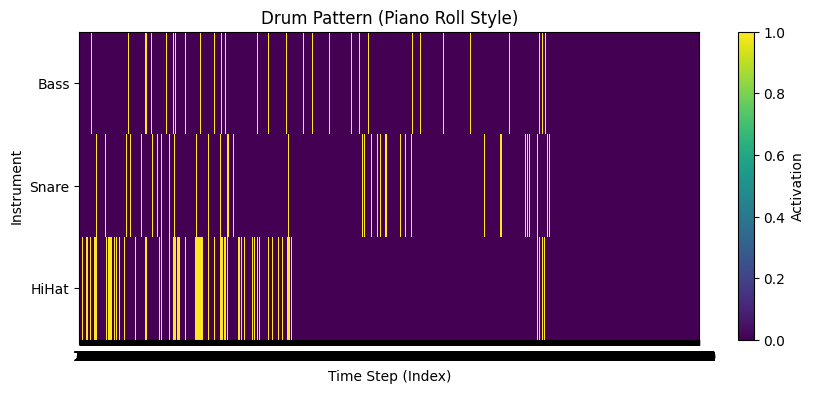

In [14]:
# vectorize the midi track
midi_file = mido.MidiFile(midifile_path)
vectors = midi_to_vector(midi_file, TICKS_PER_STEP)
viz_vectors(vectors)# it takes a lot of time

# Play the audio

In [15]:
from mido import Message, MetaMessage, MidiFile, MidiTrack, bpm2tempo, second2tick

time = TICKS_PER_STEP 
channel =  9
program = 0
bn = 36
sd = 38
hh = 42

velocity = 64

def vectors_to_midi(vectors, ticks_per_beat=240):
  mid = MidiFile()
  mid.ticks_per_beat = int(TICKS_PER_STEP * multiplier)

  track = MidiTrack()
  mid.tracks.append(track)

  # mido time - delta time - the number of ticks to wait since the previous message

# MetaMessage('set_tempo', tempo=428571, time=0)
# MetaMessage('time_signature', numerator=4, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
# MetaMessage('key_signature', key='C', time=0)
# MetaMessage('end_of_track', time=1)
# Ticks per quarter note: 480
  track.append(MetaMessage('key_signature', key='C', time=0))
  track.append(MetaMessage('set_tempo', tempo=bpm2tempo(140) , time=0))
  track.append(MetaMessage('time_signature', numerator=4, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0))

  track.append(Message('program_change', program=0, time=0, channel=channel))
  track.append(Message('control_change', control=4, value=62, time=0, channel=channel))

  for vector in vectors:

    is_silent = all(bit == 0 for bit in vector)

    if is_silent:
        track.append(Message('note_on', channel=9, note=0, velocity=0, time=time))
        track.append(Message('note_off', channel=9, note=0, velocity=0, time=0))
    else:
        if vector[0] == 1:
          track.append(Message('note_on', channel=channel, note=bn, velocity=velocity, time=time))
          track.append(Message('note_off', channel=channel, note=bn, velocity=velocity, time=0))

        if vector[1] == 1:
          track.append(Message('note_on', channel=channel, note=sd, velocity=velocity, time=0))
          track.append(Message('note_off', channel=channel, note=sd, velocity=velocity, time=0))

        if vector[2] == 1:
          track.append(Message('note_on', channel=channel, note=hh, velocity=velocity, time=0))
          track.append(Message('note_off', channel=channel, note=hh, velocity=velocity, time=0))

  track.append(MetaMessage('end_of_track'))

  mid.save('output.mid')
  return mid


In [16]:
from mido import MidiFile


print(TICKS_PER_STEP)
new_midi: MidiFile = vectors_to_midi(vectors, TICKS_PER_STEP)
new_midi.ticks_per_beat

60


480

In [17]:
import fluidsynth

# fluidsynth -ni TSC-105.sf2 output.mid -F out.wav
def play_midi(midi_file_path, soundfont_path):
    # Initialize FluidSynth
    fs = fluidsynth.Synth()

    # Load the SoundFont
    sfid = fs.sfload(soundfont_path)
    fs.program_select(0, sfid, 0, 0)

    # Play the MIDI file
    with open(midi_file_path, "rb") as midi_file:
        midi_data = midi_file.read()

    # Feed MIDI data to FluidSynth
    fs.start()
    for msg in mido.MidiFile(midi_file_path):
        if not msg.is_meta:
            fs.midi_in(msg.bytes())

    # Wait for playback to finish
    import time
    time.sleep(10)  # Adjust as needed

    # Clean up
    fs.delete()


In [18]:
# new_midi.save('output_drum_pattern.mid')

# play_midi('output_drum_pattern.mid', "../SALC5-Light-SF-v2_7/SalC5Light2.sf2")